In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt

## Data

In [15]:
data1 = pd.read_excel('../data/raw/wer_MC_data_org.xlsx', sheet_name='CSTB_processed')
data2 = pd.read_excel('../data/raw/wer_MC_data_org.xlsx', sheet_name='GBDB_data')
important_columns = ['bldg_use_type', 'bldg_use_subtype', 'bldg_project_status', 'site_country', 'bldg_area_gfa', 'bldg_floors_ag', 'bldg_floors_bg', 'bldg_struct_type', 'bldg_roof_type', 'inv_mat_1_type', 'GHG_sum_em_m2a']
data1 = data1[important_columns]
data2 = data2[important_columns]
data = pd.concat([data1, data2], ignore_index=True)
print(data.shape)
data = data.drop_duplicates()
print(data.shape)
data

(1781, 11)
(1701, 11)


,bldg_use_type,bldg_use_subtype,bldg_project_status,site_country,bldg_area_gfa,bldg_floors_ag,bldg_floors_bg,bldg_struct_type,bldg_roof_type,inv_mat_1_type,GHG_sum_em_m2a
0,Residential,Single family house,New Built,France,96.0,0.0,0.0,massive brick,Other,"Ceramics (e.g., fired clay bricks)",11.430481
1,Residential,Single family house,New Built,France,93.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.222277
2,Residential,Single family house,New Built,France,104.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.183415
3,Residential,Multi-family house,New Built,France,1106.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.303147
4,Residential,Multi-family house,New Built,France,1518.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.071612
...,...,...,...,...,...,...,...,...,...,...,...
1776,Residential,Single family house,New Built,USA,NaN,1.0,NaN,frame concrete,No data,No data,3.490000
1777,Residential,Single family house,New Built,USA,NaN,1.0,NaN,frame wood,No data,No data,2.680000
1778,Residential,Single family house,New Built,USA,NaN,1.0,NaN,frame steel,No data,No data,2.810000
1779,Residential,Single family house,New Built,USA,NaN,2.0,1.0,frame wood,Gable or saddle roof,"Earth (e.g., unfired clay, adobe, rammed earth...",6.680000


In [16]:
no_nulls = data[data.notnull().all(axis=1)]
print(no_nulls.shape)
no_nulls = no_nulls[~no_nulls.astype(str).apply(lambda col: col.str.contains("No data", regex=False)).any(axis=1)]
print(no_nulls.shape)
no_nulls

(612, 11)
(559, 11)


,bldg_use_type,bldg_use_subtype,bldg_project_status,site_country,bldg_area_gfa,bldg_floors_ag,bldg_floors_bg,bldg_struct_type,bldg_roof_type,inv_mat_1_type,GHG_sum_em_m2a
0,Residential,Single family house,New Built,France,96.0,0.0,0.0,massive brick,Other,"Ceramics (e.g., fired clay bricks)",11.430481
1,Residential,Single family house,New Built,France,93.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.222277
2,Residential,Single family house,New Built,France,104.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.183415
3,Residential,Multi-family house,New Built,France,1106.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.303147
4,Residential,Multi-family house,New Built,France,1518.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.071612
...,...,...,...,...,...,...,...,...,...,...,...
1612,Residential,Multi-family house,New Built,Italy,2968.0,7.0,1.0,massive brick,Single pitched roof,Concrete w/o reinforcement,10.500000
1627,Residential,Single family house,New Built,Italy,367.0,2.0,1.0,frame concrete,Other,Concrete w/o reinforcement,10.800000
1761,Non-residential,Office,New Built,USA,14715.0,8.0,3.0,frame wood,Flat roof,Concrete w/o reinforcement,6.670400
1772,Non-residential,Office,New Built,USA,14715.0,8.0,3.0,frame concrete,Flat roof,Concrete w/o reinforcement,9.007200


## Target variable

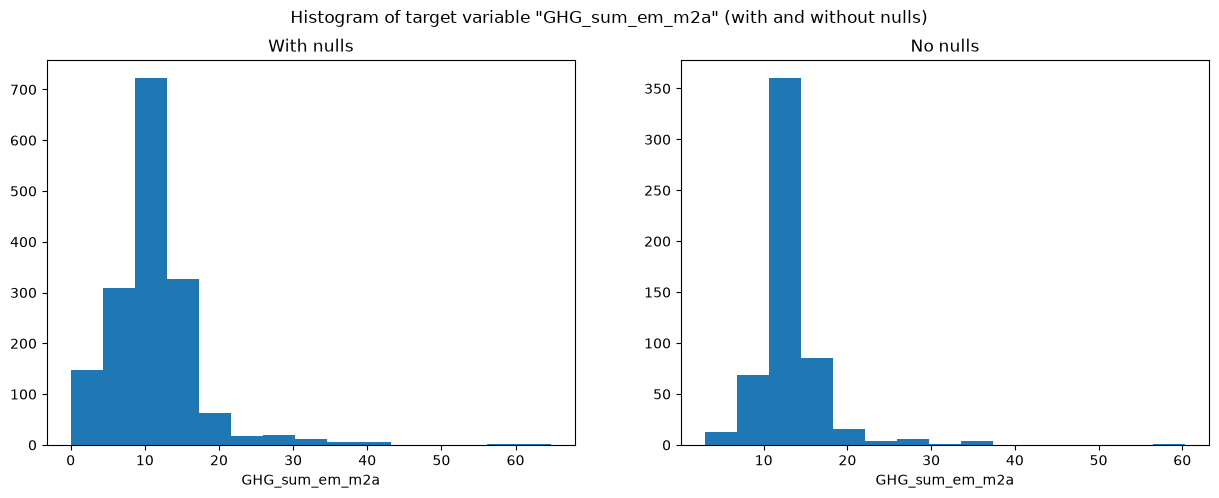

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Histogram of target variable "GHG_sum_em_m2a" (with and without nulls)')
axes[0].hist(data['GHG_sum_em_m2a'], bins=15)
axes[0].set_title('With nulls')
axes[0].set_xlabel('GHG_sum_em_m2a')
axes[1].hist(no_nulls['GHG_sum_em_m2a'], bins=15)
axes[1].set_title('No nulls')
axes[1].set_xlabel('GHG_sum_em_m2a')
plt.show()

## Possible parameters

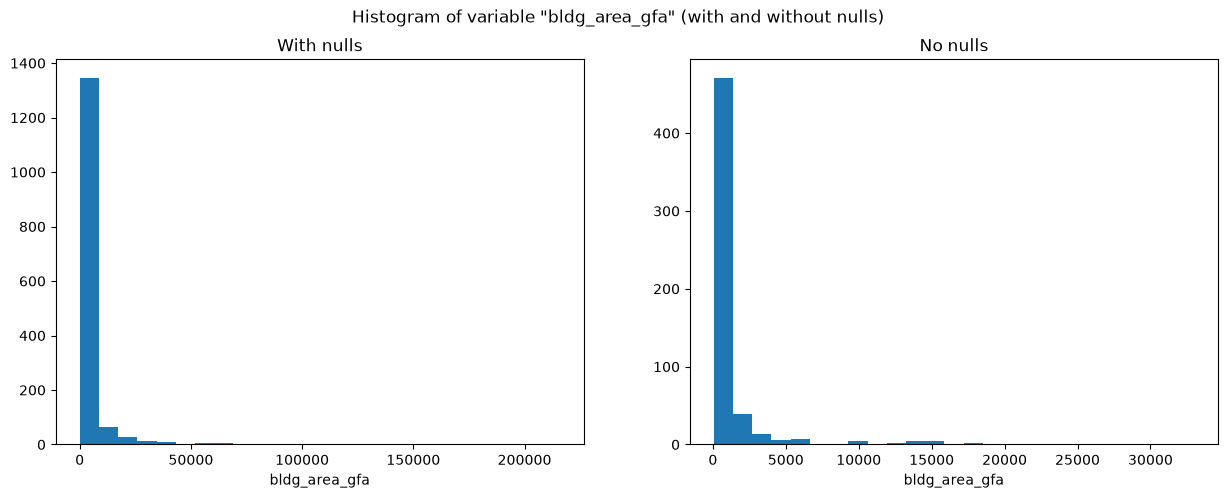

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Histogram of variable "bldg_area_gfa" (with and without nulls)')
axes[0].hist(data['bldg_area_gfa'], bins=25)
axes[0].set_title('With nulls')
axes[0].set_xlabel('bldg_area_gfa')
axes[1].hist(no_nulls['bldg_area_gfa'], bins=25)
axes[1].set_title('No nulls')
axes[1].set_xlabel('bldg_area_gfa')
plt.show()

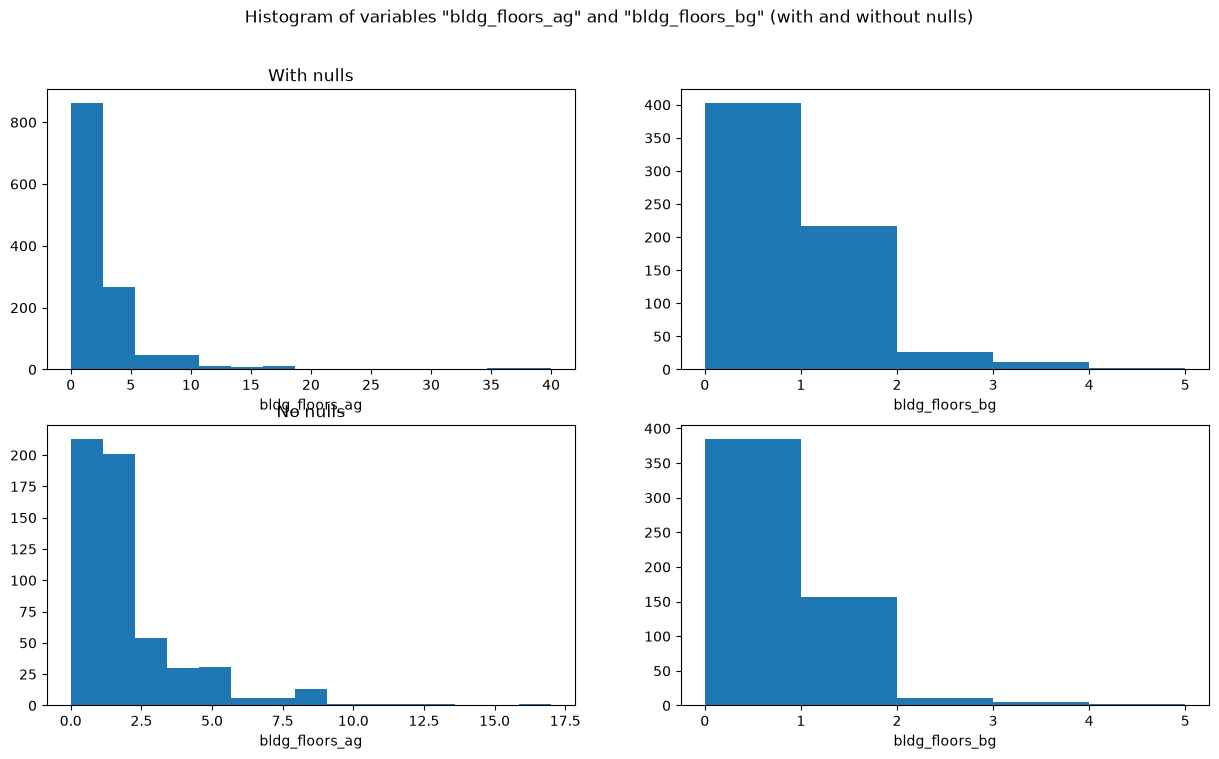

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
fig.suptitle('Histogram of variables "bldg_floors_ag" and "bldg_floors_bg" (with and without nulls)')
axes[0][0].hist(data['bldg_floors_ag'], bins=15)
axes[0][0].set_title('With nulls')
axes[0][0].set_xlabel('bldg_floors_ag')
axes[0][1].hist(data['bldg_floors_bg'], bins=5)
axes[0][1].set_xlabel('bldg_floors_bg')
axes[1][0].hist(no_nulls['bldg_floors_ag'], bins=15)
axes[1][0].set_title('No nulls')
axes[1][0].set_xlabel('bldg_floors_ag')
axes[1][1].hist(no_nulls['bldg_floors_bg'], bins=5)
axes[1][1].set_xlabel('bldg_floors_bg')
plt.show()

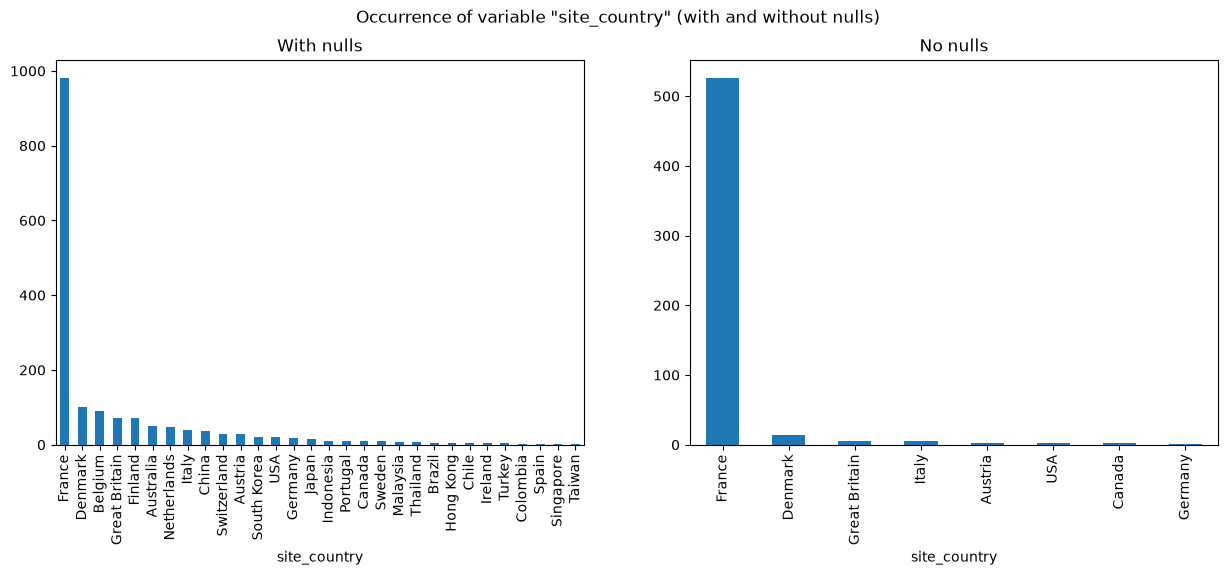

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Occurrence of variable "site_country" (with and without nulls)')
data["site_country"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("With nulls")
axes[0].set_xlabel("site_country")
no_nulls["site_country"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("No nulls")
axes[1].set_xlabel("site_country")
plt.show()

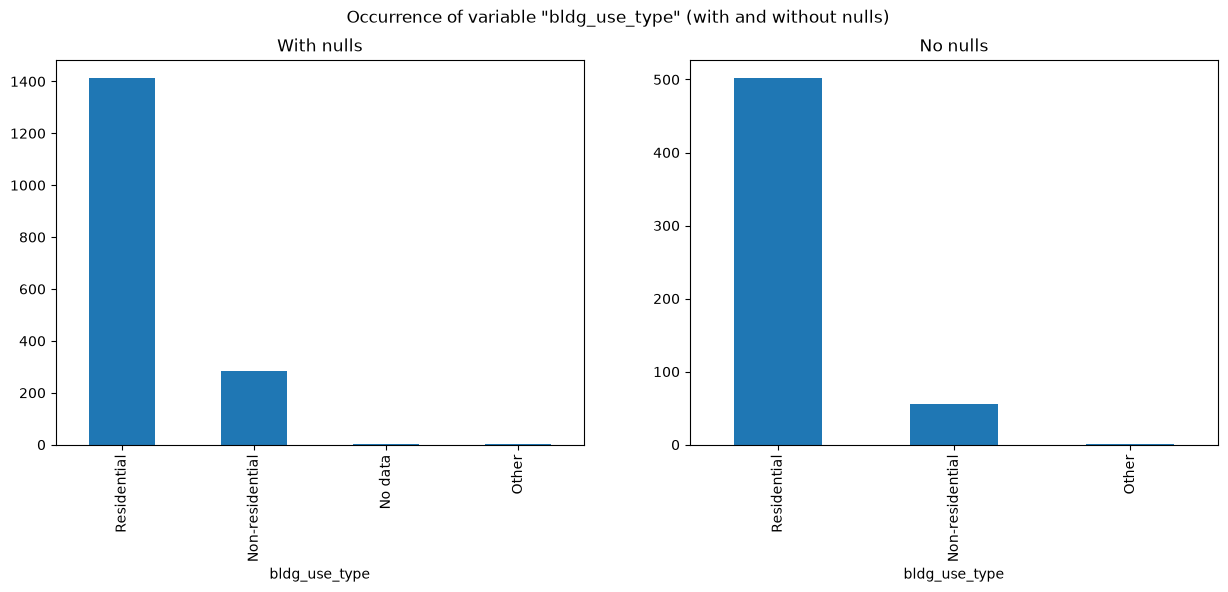

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Occurrence of variable "bldg_use_type" (with and without nulls)')
data["bldg_use_type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("With nulls")
axes[0].set_xlabel("bldg_use_type")
no_nulls["bldg_use_type"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("No nulls")
axes[1].set_xlabel("bldg_use_type")
plt.show()

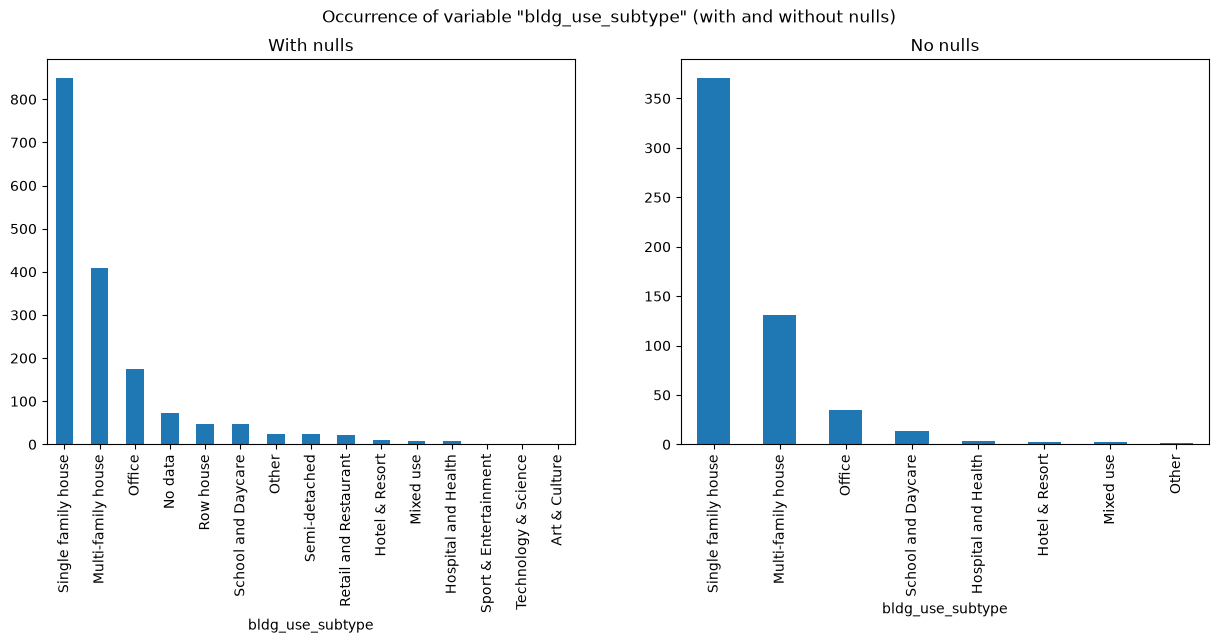

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Occurrence of variable "bldg_use_subtype" (with and without nulls)')
data["bldg_use_subtype"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("With nulls")
axes[0].set_xlabel("bldg_use_subtype")
no_nulls["bldg_use_subtype"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("No nulls")
axes[1].set_xlabel("bldg_use_subtype")
plt.show()

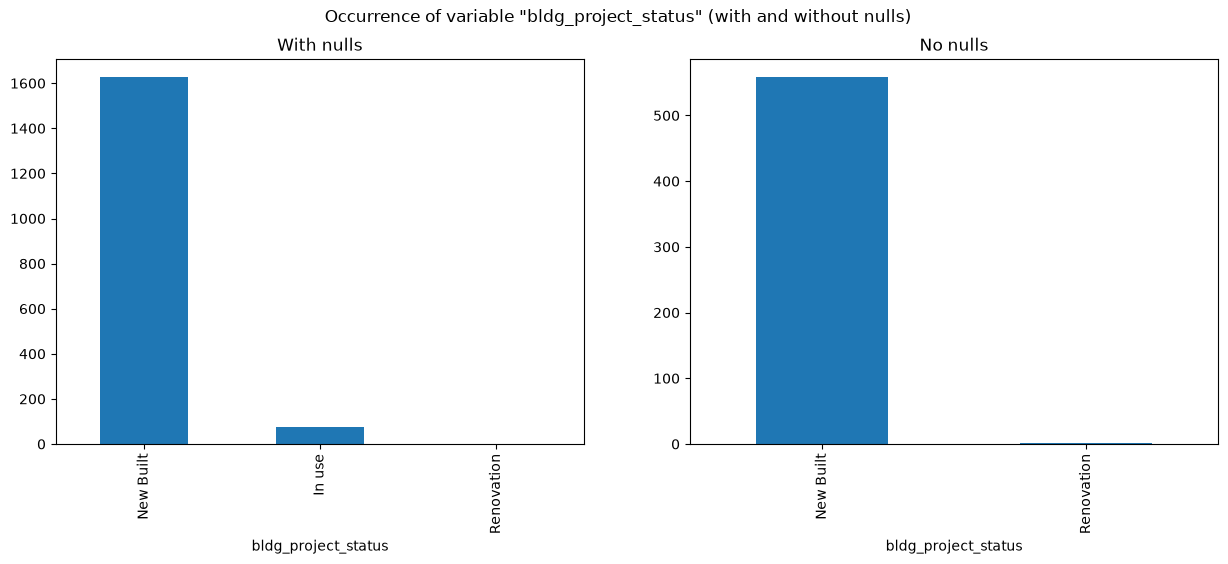

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Occurrence of variable "bldg_project_status" (with and without nulls)')
data["bldg_project_status"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("With nulls")
axes[0].set_xlabel("bldg_project_status")
no_nulls["bldg_project_status"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("No nulls")
axes[1].set_xlabel("bldg_project_status")
plt.show()

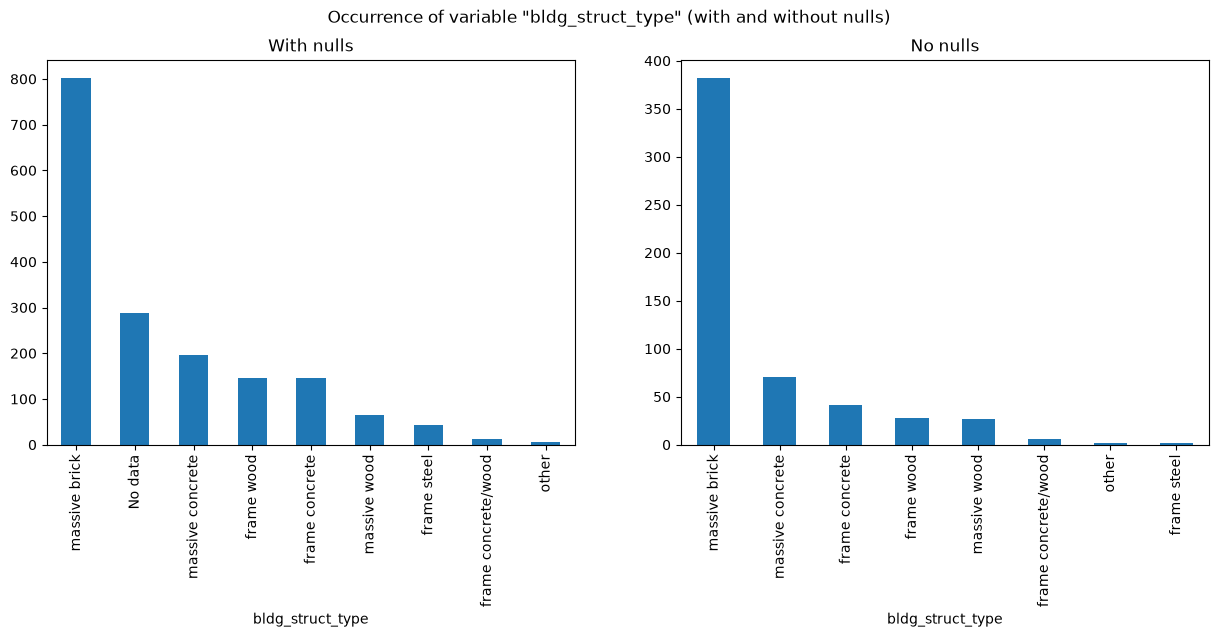

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Occurrence of variable "bldg_struct_type" (with and without nulls)')
data["bldg_struct_type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("With nulls")
axes[0].set_xlabel("bldg_struct_type")
no_nulls["bldg_struct_type"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("No nulls")
axes[1].set_xlabel("bldg_struct_type")
plt.show()

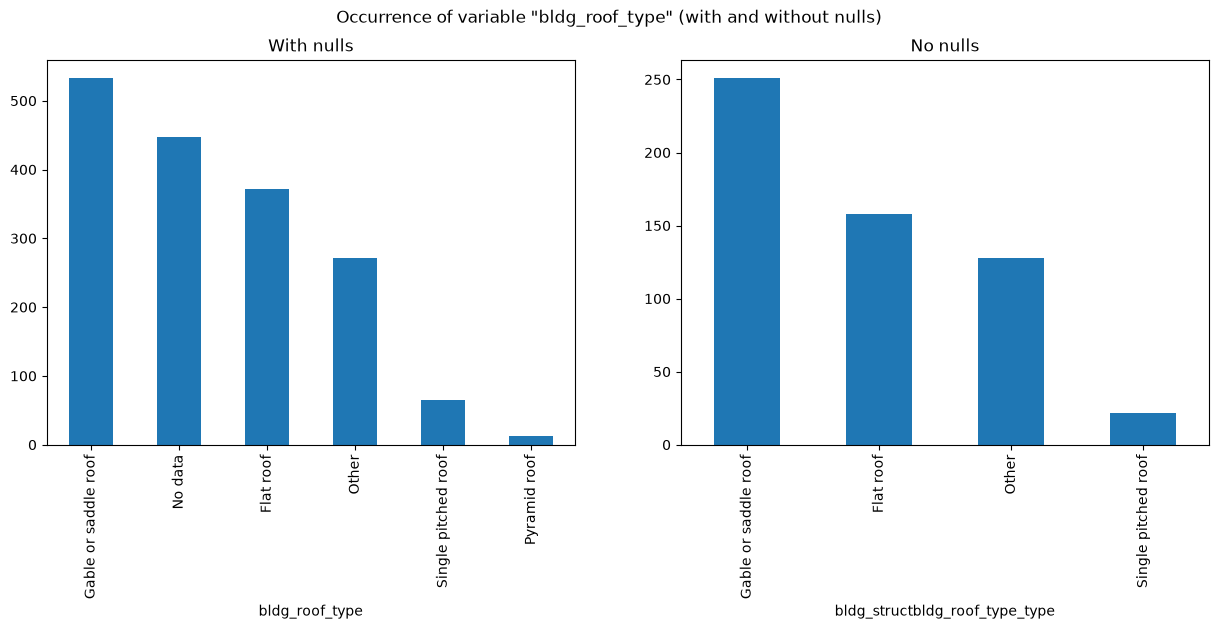

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Occurrence of variable "bldg_roof_type" (with and without nulls)')
data["bldg_roof_type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("With nulls")
axes[0].set_xlabel("bldg_roof_type")
no_nulls["bldg_roof_type"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("No nulls")
axes[1].set_xlabel("bldg_structbldg_roof_type_type")
plt.show()

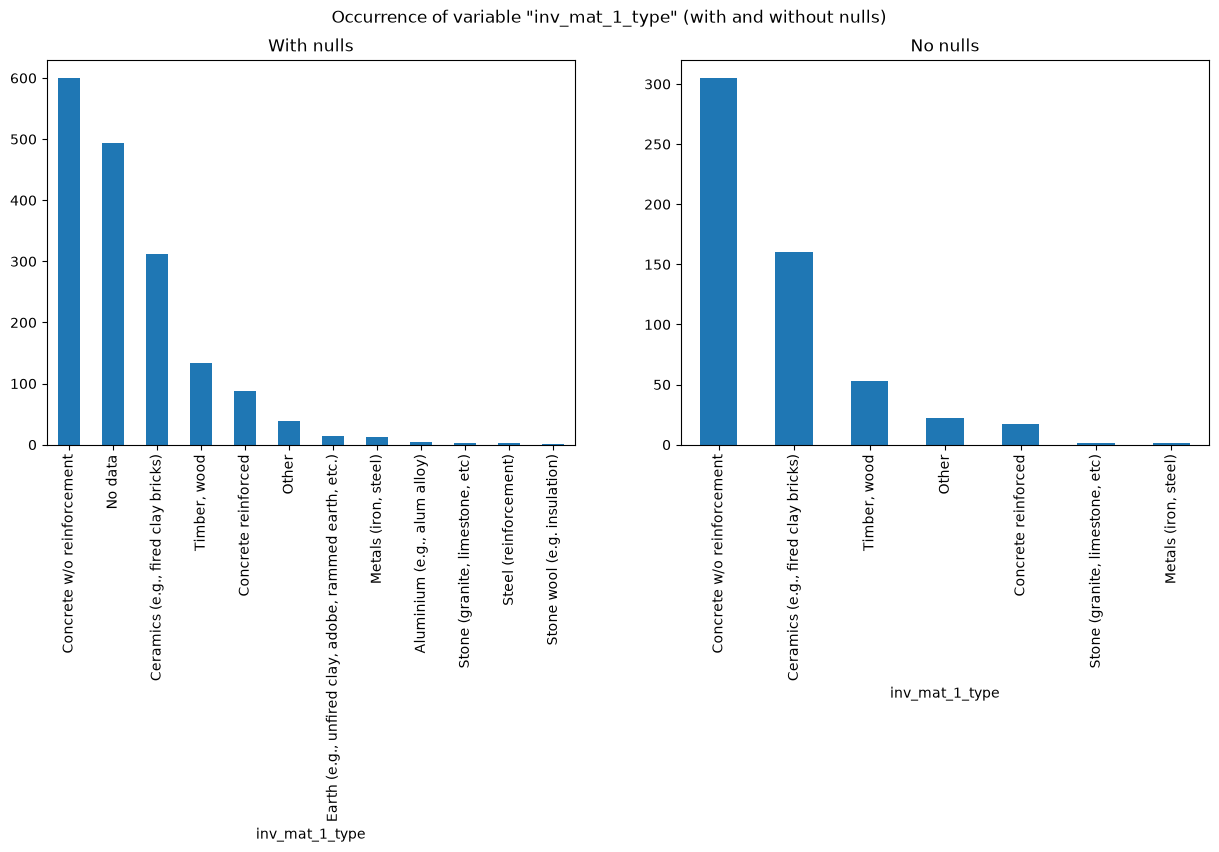

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Occurrence of variable "inv_mat_1_type" (with and without nulls)')
data["inv_mat_1_type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("With nulls")
axes[0].set_xlabel("inv_mat_1_type")
no_nulls["inv_mat_1_type"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("No nulls")
axes[1].set_xlabel("inv_mat_1_type")
plt.show()

## Correlation

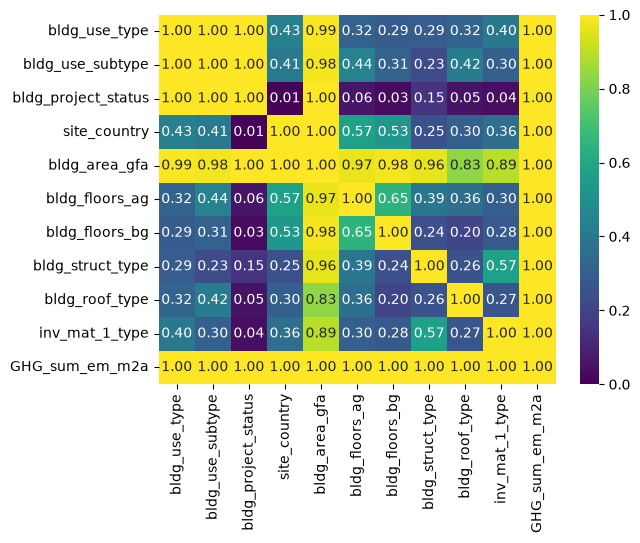

In [29]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))) if min(r, k) > 1 else np.nan

cols = no_nulls.columns
corr = pd.DataFrame(
    [[cramers_v(no_nulls[a], no_nulls[b]) for b in cols] for a in cols],
    index=cols, columns=cols,
)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.show()

The heatmap shows that every column correlates perfectly with out target. This is due to the target variable having (almost) only unique values:

In [33]:
no_nulls["GHG_sum_em_m2a"].nunique()

558

For a better result, we have to bin our target variable (makes more sense anyway: "How likely is it that the GHG_sum_em_m2a lies within this range?")

In [36]:
no_nulls["GHG_sum_em_m2a"] = np.round(no_nulls["GHG_sum_em_m2a"].astype(float), 4)
no_nulls["binned_target"] = pd.qcut(no_nulls["GHG_sum_em_m2a"], q=5, duplicates="drop")
no_nulls

,bldg_use_type,bldg_use_subtype,bldg_project_status,site_country,bldg_area_gfa,bldg_floors_ag,bldg_floors_bg,bldg_struct_type,bldg_roof_type,inv_mat_1_type,GHG_sum_em_m2a,binned_target
0,Residential,Single family house,New Built,France,96.0,0.0,0.0,massive brick,Other,"Ceramics (e.g., fired clay bricks)",11.4305,"(10.993, 11.857]"
1,Residential,Single family house,New Built,France,93.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.2223,"(10.993, 11.857]"
2,Residential,Single family house,New Built,France,104.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.1834,"(10.993, 11.857]"
3,Residential,Multi-family house,New Built,France,1106.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.3031,"(12.787, 14.626]"
4,Residential,Multi-family house,New Built,France,1518.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.0716,"(12.787, 14.626]"
...,...,...,...,...,...,...,...,...,...,...,...,...
1612,Residential,Multi-family house,New Built,Italy,2968.0,7.0,1.0,massive brick,Single pitched roof,Concrete w/o reinforcement,10.5000,"(2.9690000000000003, 10.993]"
1627,Residential,Single family house,New Built,Italy,367.0,2.0,1.0,frame concrete,Other,Concrete w/o reinforcement,10.8000,"(2.9690000000000003, 10.993]"
1761,Non-residential,Office,New Built,USA,14715.0,8.0,3.0,frame wood,Flat roof,Concrete w/o reinforcement,6.6704,"(2.9690000000000003, 10.993]"
1772,Non-residential,Office,New Built,USA,14715.0,8.0,3.0,frame concrete,Flat roof,Concrete w/o reinforcement,9.0072,"(2.9690000000000003, 10.993]"


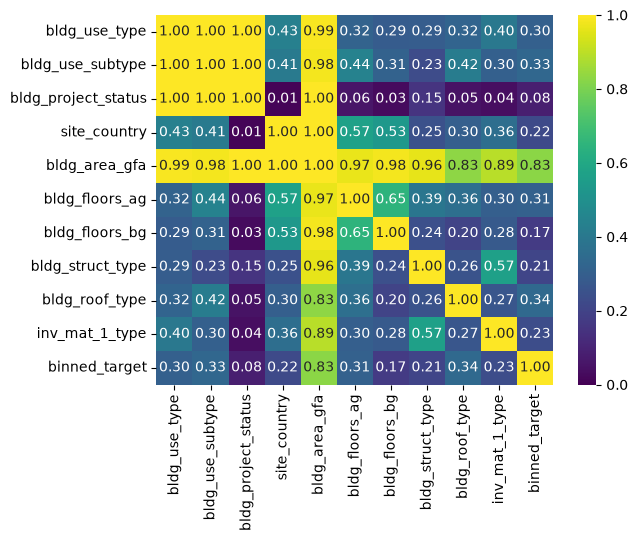

In [38]:
cols = [col for col in no_nulls.columns if col != "GHG_sum_em_m2a"]
corr = pd.DataFrame(
    [[cramers_v(no_nulls[a], no_nulls[b]) for b in cols] for a in cols],
    index=cols, columns=cols,
)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.show()